<a href="https://colab.research.google.com/github/2102508667-cloud/AI_Powered_Fraud_Detection_System/blob/main/AI_Powered_Fraud_Detection_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Powered Fraud Detection System

This repository contains a working prototype of an **AI-Powered Fraud Detection System** designed to identify suspicious financial activities and block fraudulent transactions in real time.

---

## 📌 Project Overview

In the modern financial ecosystem, quick and accurate fraud detection is crucial. Traditional rule-based systems often fail to adapt to complex, evolving fraud patterns. This project addresses this challenge by utilizing **Machine Learning (Artificial Intelligence)** to analyze multiple transaction dimensions simultaneously (amount, location distance, time, and frequency anomaly metrics) to flag suspicious transactions instantly.

### 👥 Course & Assignment Context
* **Assignment:** Build a working AI project addressing a real-world financial problem.
* **Objective:** Demonstrate how AI assists in risk assessment, build an interactive prototype with a user-friendly interface, and present practical financial application benefits.

---

## 🚀 Key Features & Functionality

1. **Synthetic Financial Transaction Engine:** Generates realistic normal and anomalous/fraudulent transaction profiles.
2. **Machine Learning Classifier:** Trains a robust **Random Forest Classifier** utilizing standardized scaling to differentiate legitimate patterns from fraud with high precision.
3. **Real-Time Interactive Interface:** Features an interactive dashboard built using `ipywidgets` allowing users to simulate transaction scenarios (by modifying parameters like dollar amount, distance, transaction hour, and velocity score) and immediately view the AI model's assessment.
4. **Actionable Decision Output:** Categorizes transactions into three status levels:
   * ✅ **Approved:** Automated approval for low-risk transactions.
   * ⚠️ **Suspicious (Hold for Review):** Flags borderline anomalies for manual investigation.
   * 🚨 **High Risk / Blocked:** Instantly blocks transaction and triggers automated customer verification recommendations.

---

## 🧠 How AI is Used in the Project

* **Feature Engineering & Scaler:** Transaction properties are normalized using a `StandardScaler` to ensure features with different units (miles, hours, dollars) contribute appropriately to predictions.
* **Decision Trees & Ensembles:** The core predictive engine is a **Random Forest Classifier**. It aggregates multiple decision pathways to assess risk based on non-linear boundaries (e.g., high transaction amounts occurring during late hours far from home).
* **Probability Mapping:** Instead of returning a simple binary label, the AI estimates a continuous probability score (`predict_proba`), allowing the system to apply customized operational rules based on financial risk thresholds.

---

## 🛠️ Technology Stack

* **Language:** Python 3
* **Data Processing:** `pandas`, `numpy`
* **Machine Learning:** `scikit-learn` (Random Forest, StandardScaler, Model Evaluation)
* **Visualization:** `matplotlib`, `seaborn`
* **User Interface:** `ipywidgets` (Interactive slider elements and HTML styling)

---

## 💻 Getting Started

### Run on Google Colab
Simply upload or open this notebook directly in Google Colab, and click **Runtime > Run All** to generate the dataset, train the machine learning model, and launch the interactive testing dashboard.

# AI-Powered Fraud Detection System

This notebook implements a complete working prototype of an AI-Powered Fraud Detection System designed to analyze financial transactions and identify potentially fraudulent activities based on unusual transaction patterns.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual

# Set random seed for reproducibility
np.random.seed(42)
print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Synthetic Data Generation
We will generate synthetic financial transaction records including amount, time of day, location distance from home, and frequency of transactions to build a classifier.

In [ ]:
def generate_transaction_data(num_samples=5000):
    # Normal transactions
    normal_amounts = np.random.exponential(scale=50, size=int(num_samples * 0.95)) + 1
    normal_distances = np.random.exponential(scale=5, size=int(num_samples * 0.95))
    normal_hours = np.random.uniform(7, 23, size=int(num_samples * 0.95))
    normal_risk = np.random.uniform(0, 0.3, size=int(num_samples * 0.95))

    # Fraudulent transactions (characterized by unusual patterns: high amount, long distance, unusual hours)
    fraud_amounts = np.random.normal(loc=800, scale=200, size=int(num_samples * 0.05))
    fraud_amounts = np.clip(fraud_amounts, a_min=100, a_max=None)
    fraud_distances = np.random.normal(loc=150, scale=50, size=int(num_samples * 0.05))
    fraud_distances = np.clip(fraud_distances, a_min=20, a_max=None)
    fraud_hours = np.concatenate([
        np.random.uniform(0, 5, size=int(num_samples * 0.025)),
        np.random.uniform(23, 24, size=int(num_samples * 0.025))
    ])
    fraud_risk = np.random.uniform(0.7, 1.0, size=int(num_samples * 0.05))

    # Combine datasets
    amounts = np.concatenate([normal_amounts, fraud_amounts])
    distances = np.concatenate([normal_distances, fraud_distances])
    hours = np.concatenate([normal_hours, fraud_hours])
    risk_score = np.concatenate([normal_risk, fraud_risk])
    labels = np.concatenate([np.zeros(len(normal_amounts)), np.ones(len(fraud_amounts))])

    df = pd.DataFrame({
        'transaction_amount': amounts,
        'distance_from_home': distances,
        'hour_of_day': hours,
        'velocity_score': risk_score,
        'is_fraud': labels.astype(int)
    })

    # Shuffle the dataset
    return df.sample(frac=1).reset_index(drop=True)

df = generate_transaction_data()
display(df.head())
print(f"Dataset shape: {df.shape}")
print(f"Class distribution:\n{df['is_fraud'].value_counts(normalize=True)}")

,transaction_amount,distance_from_home,hour_of_day,velocity_score,is_fraud
0,41.227079,6.658151,12.374622,0.093757,0
1,10.877034,0.690445,17.590249,0.185427,0
2,46.888884,0.244803,11.035123,0.279904,0
3,9.790418,8.258289,10.940332,0.237033,0
4,52.627782,0.405394,22.123017,0.262780,0


Dataset shape: (5000, 5)
Class distribution:
is_fraud
0    0.95
1    0.05
Name: proportion, dtype: float64


## 2. Model Training and Evaluation
We will train a Random Forest Classifier to detect unusual transaction patterns.

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       950
           1       1.00      1.00      1.00        50

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



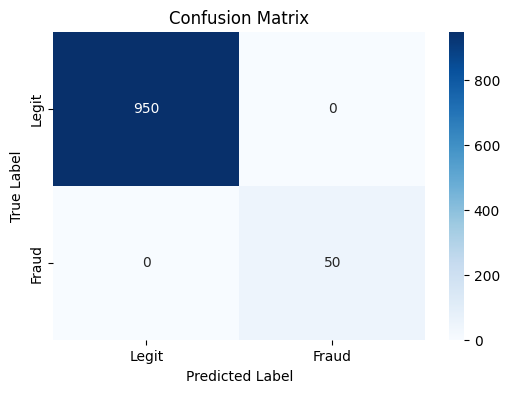

In [ ]:
X = df.drop('is_fraud', axis=1)
y = df['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 3. Interactive Real-Time Fraud Detector Interface
This widget demonstrates the system's practical application, allowing users to tweak transaction parameters and observe how the AI assesses the risk level.

In [ ]:
def evaluate_custom_transaction(amount, distance, hour, velocity):
    custom_data = pd.DataFrame([{
        'transaction_amount': amount,
        'distance_from_home': distance,
        'hour_of_day': hour,
        'velocity_score': velocity
    }])

    custom_scaled = scaler.transform(custom_data)
    prediction = model.predict(custom_scaled)[0]
    probability = model.predict_proba(custom_scaled)[0][1]

    print("=" * 50)
    print("         AI TRANSACTION ASSESSMENT RESULT         ")
    print("=" * 50)
    print(f"Transaction Amount       : ${amount:.2f}")
    print(f"Distance from Home       : {distance:.1f} miles")
    print(f"Time of Day              : {int(hour):02d}:00")
    print(f"Velocity/Anomaly Score   : {velocity:.2f}")
    print("-" * 50)
    print(f"Calculated Fraud Probability: {probability * 100:.2f}%")

    if probability > 0.7:
        print("\033[91m🚨 STATUS: HIGH RISK / BLOCKED (POSSIBLE FRAUD) 🚨\033[0m")
        print("Recommendation: Alert owner, request verification code immediately.")
    elif probability > 0.3:
        print("\033[93m⚠️ STATUS: SUSPICIOUS / HOLD FOR REVIEW ⚠️\033[0m")
        print("Recommendation: Flag for manual agent investigation.")
    else:
        print("\033[92m✅ STATUS: APPROVED ✅\033[0m")
        print("Recommendation: Auto-approved.")
    print("=" * 50)

# Build user interface controls
amount_slider = widgets.FloatSlider(min=1.0, max=2000.0, step=10.0, value=50.0, description='Amount ($):')
distance_slider = widgets.FloatSlider(min=0.0, max=500.0, step=5.0, value=5.0, description='Dist. (mi):')
hour_slider = widgets.IntSlider(min=0, max=23, step=1, value=12, description='Hour (0-23):')
velocity_slider = widgets.FloatSlider(min=0.0, max=1.0, step=0.05, value=0.15, description='Anomaly Score:')

ui = widgets.VBox([amount_slider, distance_slider, hour_slider, velocity_slider])
out = widgets.interactive_output(evaluate_custom_transaction, {
    'amount': amount_slider,
    'distance': distance_slider,
    'hour': hour_slider,
    'velocity': velocity_slider
})

display(ui, out)

Output()